In [2]:
OUTPUT_FOLDER = "../submission"

<Figure size 640x480 with 0 Axes>

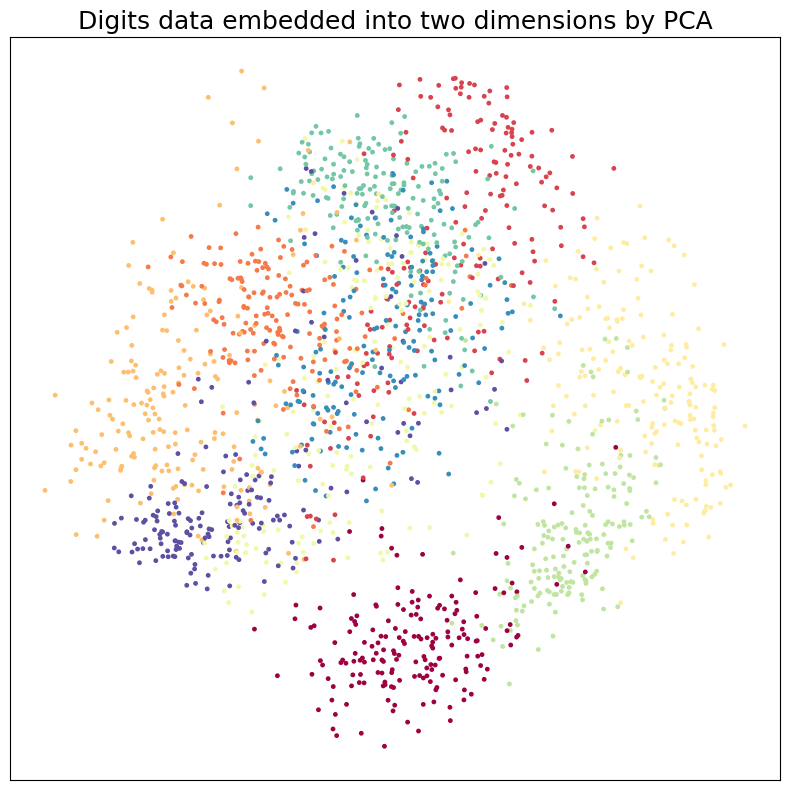

Figura guardada en: ../submission/digits_pca.png


In [4]:

# ============================================================
# PRE 14 - ANÁLISIS DE COMPONENTES PRINCIPALES (PCA)
# Manu | Visualización de dígitos en dos dimensiones
# ============================================================

from pathlib import Path

def pca():
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.decomposition import PCA
    from sklearn.datasets import load_digits

    # Manu: Cargar los datos de dígitos escritos a mano
    digitos = load_digits()

    X = digitos.data
    y = digitos.target

    # Manu: Reducir la información a dos componentes principales
    modelo_pca = PCA(n_components=2)
    componentes = modelo_pca.fit_transform(X)

    # Manu: Unir los componentes con las etiquetas originales
    datos_pca = np.column_stack((componentes, y))

    tabla_pca = pd.DataFrame(
        datos_pca,
        columns=["1st_principal", "2nd_principal", "label"]
    )

    # Manu: Crear la gráfica de dispersión
    figura, eje = plt.subplots(figsize=(8, 8))

    puntos = eje.scatter(
        tabla_pca["1st_principal"],
        tabla_pca["2nd_principal"],
        c=tabla_pca["label"],
        cmap="Spectral",
        s=6
    )

    # Manu: Configurar la presentación de la figura
    eje.set_xticks([])
    eje.set_yticks([])
    eje.set_title(
        "Digits data embedded into two dimensions by PCA",
        fontsize=18
    )

    figura.tight_layout()

    # Manu: Conservar la carpeta de salida del notebook
    carpeta_salida = Path(OUTPUT_FOLDER)
    carpeta_salida.mkdir(parents=True, exist_ok=True)

    ruta_imagen = carpeta_salida / "digits_pca.png"

    # Manu: Primero guardar y después mostrar
    figura.savefig(ruta_imagen, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(figura)

    print("Figura guardada en:", ruta_imagen)

    return tabla_pca


# Manu: Ejecutar el análisis PCA
resultado_pca = pca()


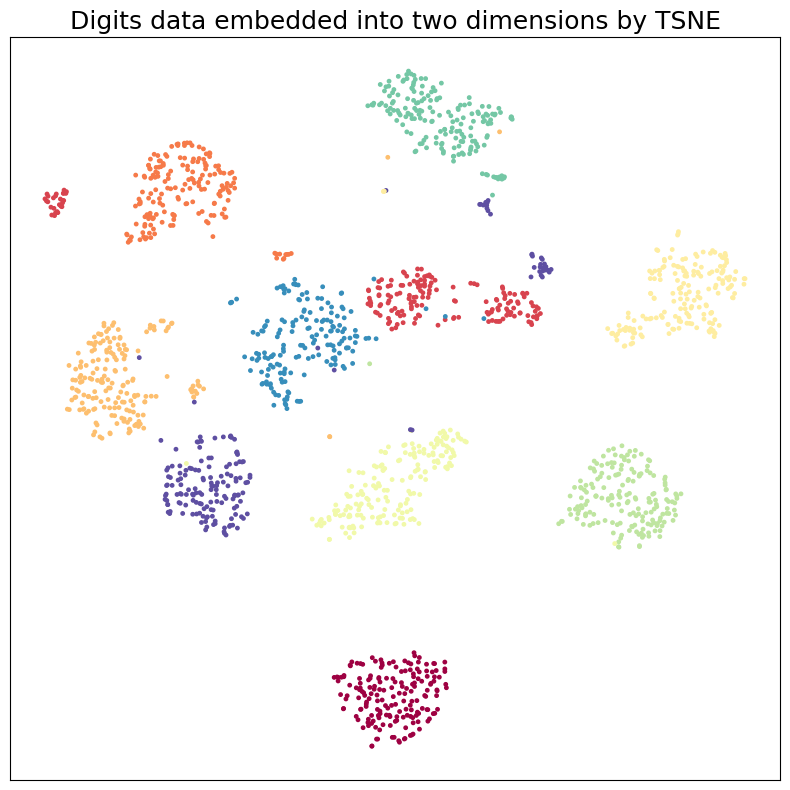

Figura guardada correctamente en: ../submission/digits_tsne.png


In [6]:

# ============================================================
# PRE 14 - REDUCCIÓN DE DIMENSIONALIDAD
# Manu | Visualización de dígitos mediante t-SNE
# ============================================================

from pathlib import Path

def tsne():
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_digits
    from sklearn.manifold import TSNE

    # Manu: Cargar los datos de dígitos escritos a mano
    digitos = load_digits()

    X = digitos.data
    y = digitos.target

    # Manu: Reducir las variables a dos dimensiones con t-SNE
    modelo_tsne = TSNE(
        n_components=2,
        random_state=0
    )

    componentes = modelo_tsne.fit_transform(X)

    # Manu: Crear la figura de dispersión
    figura, eje = plt.subplots(figsize=(8, 8))

    eje.scatter(
        componentes[:, 0],
        componentes[:, 1],
        c=y,
        cmap="Spectral",
        s=6
    )

    # Manu: Personalizar los elementos de la gráfica
    eje.set_xticks([])
    eje.set_yticks([])

    eje.set_title(
        "Digits data embedded into two dimensions by TSNE",
        fontsize=18
    )

    figura.tight_layout()

    # Manu: Definir la carpeta para los entregables
    carpeta_salida = Path(OUTPUT_FOLDER)
    carpeta_salida.mkdir(parents=True, exist_ok=True)

    ruta_imagen = carpeta_salida / "digits_tsne.png"

    # Manu: Guardar la figura antes de mostrarla
    figura.savefig(
        ruta_imagen,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figura)

    print("Figura guardada correctamente en:", ruta_imagen)

    return componentes


# Manu: Ejecutar el análisis t-SNE
resultado_tsne = tsne()


/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


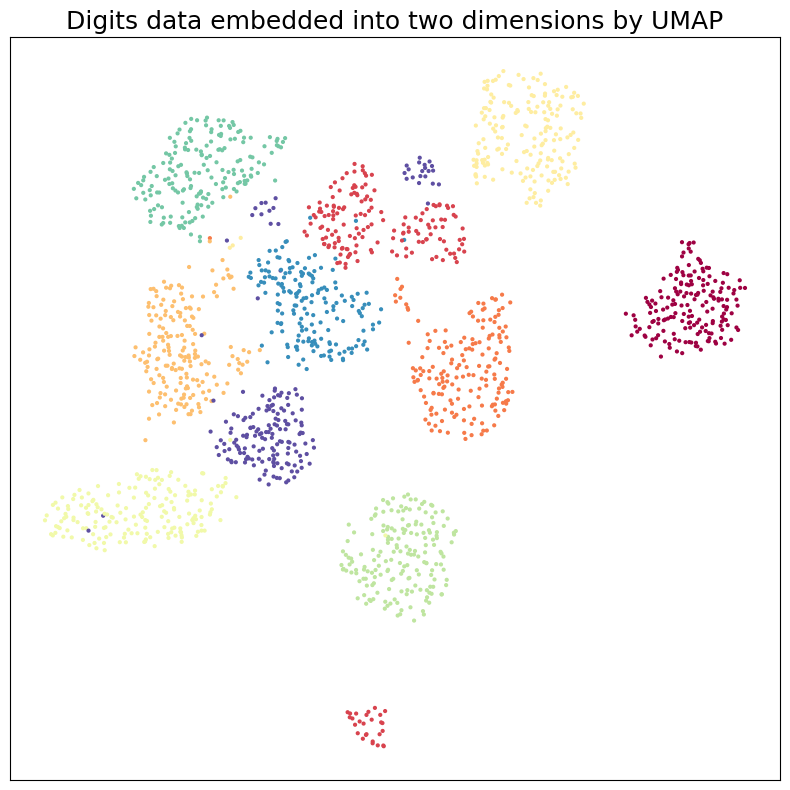

Figura guardada correctamente en: ../submission/digits_umap.png


In [3]:

# ============================================================
# PRE 14 - REDUCCIÓN DE DIMENSIONALIDAD
# Manu | Visualización de dígitos mediante UMAP
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import load_digits


def umap_projection():
    """
    Aplica UMAP para reducir las características de los
    dígitos escritos a mano a dos dimensiones.

    Genera una gráfica de dispersión y la guarda
    en la carpeta submission del laboratorio.
    """

    # ========================================================
    # 1. CARGA DE LOS DATOS
    # ========================================================

    # Manu: Cargar los dígitos escritos a mano
    digitos = load_digits()

    X = digitos.data
    y = digitos.target

    # ========================================================
    # 2. REDUCCIÓN DE DIMENSIONALIDAD
    # ========================================================

    # Manu: Configurar UMAP con los parámetros del profesor
    modelo_umap = umap.UMAP(
        n_components=2,
        random_state=42,
        min_dist=0.8
    )

    # Manu: Obtener la representación en dos dimensiones
    componentes = modelo_umap.fit_transform(X)

    # ========================================================
    # 3. VISUALIZACIÓN DE LOS RESULTADOS
    # ========================================================

    # Manu: Crear una gráfica de dispersión
    figura, eje = plt.subplots(figsize=(8, 8))

    eje.scatter(
        componentes[:, 0],
        componentes[:, 1],
        c=y,
        cmap="Spectral",
        s=4
    )

    # Manu: Quitar las marcas de los ejes
    eje.set_xticks([])
    eje.set_yticks([])

    # Manu: Agregar el título de la visualización
    eje.set_title(
        "Digits data embedded into two dimensions by UMAP",
        fontsize=18
    )

    figura.tight_layout()

    # ========================================================
    # 4. EXPORTACIÓN DE LA FIGURA
    # ========================================================

    # Manu: Definir la carpeta submission del laboratorio
    carpeta_salida = Path("../submission")

    # Manu: Crear la carpeta solamente si no existe
    carpeta_salida.mkdir(parents=True, exist_ok=True)

    # Manu: Definir el nombre del archivo de salida
    ruta_imagen = carpeta_salida / "digits_umap.png"

    # Manu: Guardar la imagen antes de mostrarla
    figura.savefig(
        ruta_imagen,
        dpi=150,
        bbox_inches="tight"
    )

    # Manu: Mostrar la gráfica en el notebook
    plt.show()

    # Manu: Cerrar la figura para liberar memoria
    plt.close(figura)

    print("Figura guardada correctamente en:", ruta_imagen)

    # Manu: Retornar los componentes obtenidos
    return componentes


# ============================================================
# 5. EJECUCIÓN DEL ANÁLISIS
# ============================================================

# Manu: Ejecutar UMAP y almacenar sus resultados
resultado_umap = umap_projection()


In [4]:
# ¿Cuántas componentes principales conservan suficiente información para clasificar el dígito, no sólo para verse bien en un gráfico?

import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

digits = load_digits()
X_train, X_test, y_train, y_test = train_test_split(
    digits.data,
    digits.target,
    test_size=0.5,
    random_state=0,
    stratify=digits.target,
)

component_counts = [2, 5, 10, 20, 30, 40, 64]
component_rows = []
for k in component_counts:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=k)),
        ("classifier", LogisticRegression(max_iter=1000)),
    ])
    pipeline.fit(X_train, y_train)
    test_accuracy = pipeline.score(X_test, y_test)
    explained_variance = pipeline.named_steps["pca"].explained_variance_ratio_.sum()
    component_rows.append({
        "k": k,
        "explained_variance": explained_variance,
        "test_accuracy": test_accuracy,
    })

pca_components_accuracy = pd.DataFrame(component_rows)
pca_components_accuracy

,k,explained_variance,test_accuracy
0,2,0.219732,0.543938
1,5,0.423248,0.812013
2,10,0.604982,0.880979
3,20,0.806500,0.935484
4,30,0.908787,0.942158
5,40,0.959915,0.952169
6,64,1.000000,0.963293


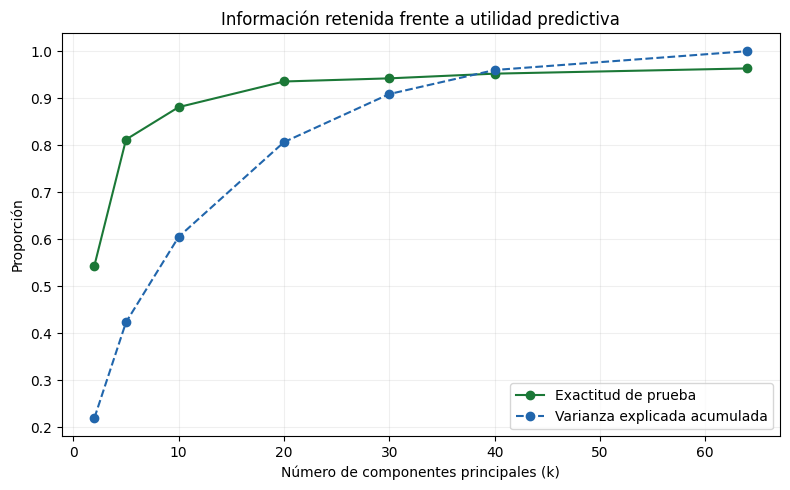

Figura guardada correctamente en: ../submission/pca_components_accuracy.png


In [6]:

# ============================================================
# PRE 14 - ANÁLISIS DE COMPONENTES PRINCIPALES
# Manu | Exactitud predictiva frente a varianza explicada
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. VERIFICACIÓN DE LOS DATOS
# ============================================================

# Manu: Comprobar que existe el resultado del análisis PCA
if "pca_components_accuracy" not in globals():
    raise NameError(
        "Primero debes ejecutar la celda que crea "
        "pca_components_accuracy."
    )

# Manu: Verificar las columnas necesarias
columnas_necesarias = [
    "k",
    "test_accuracy",
    "explained_variance"
]

for columna in columnas_necesarias:
    assert columna in pca_components_accuracy.columns, (
        f"Falta la columna: {columna}"
    )

# ============================================================
# 2. CONSTRUCCIÓN DE LA GRÁFICA
# ============================================================

# Manu: Comparar exactitud y varianza explicada
figura, eje = plt.subplots(figsize=(8, 5))

# Manu: Graficar la exactitud de prueba
eje.plot(
    pca_components_accuracy["k"],
    pca_components_accuracy["test_accuracy"],
    marker="o",
    color="#1b7837",
    label="Exactitud de prueba"
)

# Manu: Graficar la varianza explicada acumulada
eje.plot(
    pca_components_accuracy["k"],
    pca_components_accuracy["explained_variance"],
    marker="o",
    linestyle="--",
    color="#2166ac",
    label="Varianza explicada acumulada"
)

# Manu: Personalizar la presentación
eje.set_xlabel("Número de componentes principales (k)")
eje.set_ylabel("Proporción")

eje.set_title(
    "Información retenida frente a utilidad predictiva"
)

eje.legend()
eje.grid(alpha=0.2)

figura.tight_layout()

# ============================================================
# 3. GUARDAR LA FIGURA
# ============================================================

# Manu: Utilizar directamente la carpeta submission
ruta_salida = Path("../submission")
ruta_salida.mkdir(parents=True, exist_ok=True)

ruta_figura = ruta_salida / "pca_components_accuracy.png"

# Manu: Guardar antes de mostrar
figura.savefig(
    ruta_figura,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(figura)

print("Figura guardada correctamente en:", ruta_figura)


In [7]:

# ============================================================
# PRE 14 - REDUCCIÓN DE DIMENSIONALIDAD
# Manu | Evaluación de la capacidad predictiva de UMAP
# ============================================================

import pandas as pd
import umap
from sklearn.linear_model import LogisticRegression

# ============================================================
# 1. VERIFICACIÓN DE VARIABLES
# ============================================================

# Manu: Verificar que ya se ejecutaron las celdas anteriores
variables_necesarias = [
    "component_counts",
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

variables_faltantes = [
    nombre
    for nombre in variables_necesarias
    if nombre not in globals()
]

if variables_faltantes:
    raise NameError(
        "Primero debes ejecutar las celdas que definen: "
        + ", ".join(variables_faltantes)
    )

# ============================================================
# 2. EVALUACIÓN DE UMAP
# ============================================================

# Manu: Almacenar los resultados para cada número de componentes
umap_rows = []

# Manu: Evaluar UMAP con los mismos componentes utilizados en PCA
for k in component_counts:

    print(f"Evaluando UMAP con {k} componentes...")

    # Manu: Configurar el reductor dimensional
    reducer = umap.UMAP(
        n_components=int(k),
        random_state=42,
        min_dist=0.8
    )

    # Manu: Ajustar UMAP exclusivamente con datos de entrenamiento
    reducer.fit(X_train)

    # Manu: Proyectar las observaciones de entrenamiento y prueba
    train_embedding = reducer.transform(X_train)
    test_embedding = reducer.transform(X_test)

    # Manu: Entrenar el modelo de clasificación
    classifier = LogisticRegression(
        max_iter=1000
    )

    classifier.fit(train_embedding, y_train)

    # Manu: Calcular la exactitud predictiva en prueba
    test_accuracy = classifier.score(
        test_embedding,
        y_test
    )

    # Manu: Registrar los resultados del experimento
    umap_rows.append({
        "k": int(k),
        "test_accuracy": test_accuracy
    })

# ============================================================
# 3. CONSOLIDACIÓN DE RESULTADOS
# ============================================================

# Manu: Crear el DataFrame para comparar UMAP con PCA
umap_components_accuracy = pd.DataFrame(umap_rows)

# Manu: Mostrar los resultados
display(umap_components_accuracy)


Evaluando UMAP con 2 componentes...


/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Evaluando UMAP con 5 componentes...


/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. U

Evaluando UMAP con 10 componentes...
Evaluando UMAP con 20 componentes...


/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (3 outputs left out)

/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Evaluando UMAP con 64 componentes...


/Users/macbook/Desktop/Analitica predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,k,test_accuracy
0,2,0.905451
1,5,0.926585
2,10,0.954394
3,20,0.956618
4,30,0.955506
5,40,0.952169
6,64,0.954394


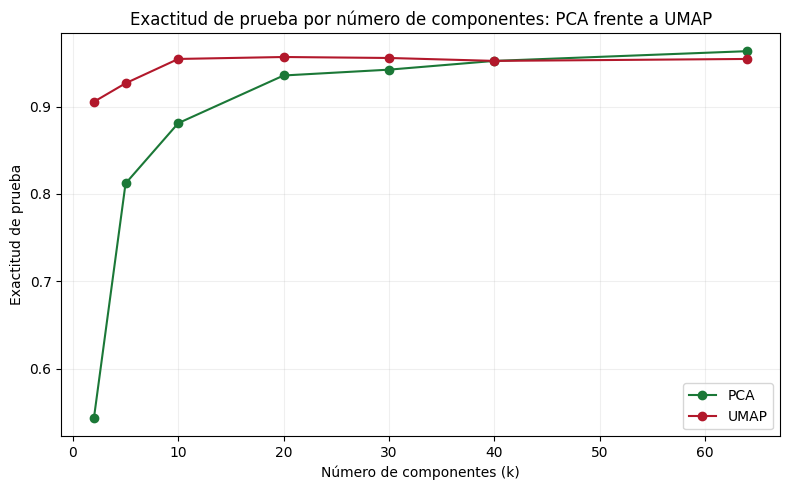

Figura guardada correctamente en: ../submission/pca_vs_umap_accuracy.png


In [8]:

# ============================================================
# PRE 14 - REDUCCIÓN DE DIMENSIONALIDAD
# Manu | Comparación de exactitud predictiva: PCA vs. UMAP
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. VERIFICACIÓN DE RESULTADOS
# ============================================================

# Manu: Comprobar que se ejecutaron los análisis de PCA y UMAP
for nombre in ["pca_components_accuracy", "umap_components_accuracy"]:
    if nombre not in globals():
        raise NameError(
            f"Primero debes ejecutar la celda que crea {nombre}."
        )

# Manu: Comprobar que ambos resultados contienen los indicadores
for nombre, datos in [
    ("PCA", pca_components_accuracy),
    ("UMAP", umap_components_accuracy)
]:
    columnas_necesarias = {"k", "test_accuracy"}

    if not columnas_necesarias.issubset(datos.columns):
        raise ValueError(
            f"Faltan columnas en los resultados de {nombre}."
        )

# ============================================================
# 2. COMPARACIÓN GRÁFICA DE LOS MODELOS
# ============================================================

# Manu: Crear la figura de comparación
figura_comparacion, eje_comparacion = plt.subplots(
    figsize=(8, 5)
)

# Manu: Graficar la exactitud predictiva obtenida mediante PCA
eje_comparacion.plot(
    pca_components_accuracy["k"],
    pca_components_accuracy["test_accuracy"],
    marker="o",
    color="#1b7837",
    label="PCA"
)

# Manu: Graficar la exactitud predictiva obtenida mediante UMAP
eje_comparacion.plot(
    umap_components_accuracy["k"],
    umap_components_accuracy["test_accuracy"],
    marker="o",
    color="#b2182b",
    label="UMAP"
)

# ============================================================
# 3. PRESENTACIÓN DE LA GRÁFICA
# ============================================================

# Manu: Agregar títulos y etiquetas
eje_comparacion.set_xlabel(
    "Número de componentes (k)"
)

eje_comparacion.set_ylabel(
    "Exactitud de prueba"
)

eje_comparacion.set_title(
    "Exactitud de prueba por número de componentes: PCA frente a UMAP"
)

# Manu: Mostrar leyenda y cuadrícula
eje_comparacion.legend()
eje_comparacion.grid(alpha=0.2)

figura_comparacion.tight_layout()

# ============================================================
# 4. EXPORTACIÓN DE RESULTADOS
# ============================================================

# Manu: Definir la carpeta de salida del laboratorio
carpeta_salida = Path("../submission")
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Manu: Definir el nombre de la figura
ruta_figura = carpeta_salida / "pca_vs_umap_accuracy.png"

# Manu: Guardar la figura antes de mostrarla
figura_comparacion.savefig(
    ruta_figura,
    dpi=150,
    bbox_inches="tight"
)

# Manu: Mostrar la comparación
plt.show()
plt.close(figura_comparacion)

print("Figura guardada correctamente en:", ruta_figura)
